## Time Series Forecasting module

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from configs.system import project_dir

In [4]:
p_dir = project_dir()

data_dir = p_dir.FEATURED_DIR
dataset_path = data_dir/'featured_dataset.csv'

In [5]:
df = pd.read_csv(dataset_path,index_col=0)
df.sample(2)

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,Duration,Demand,StartMonth,StartWeek,EndMonth,EndWeek,DemandPerMonth,StartDayOfWeek,DemandPerDay,Shift
62184,324,1157,0,sightseeing,0,2022-04-25,08:06:37,2022-04-25,10:00:01,2022-04-25 08:06:00,...,113,6.80,4,0,4,0,104253.67,Monday,17.35,Day
46550,449,492,1,company,0,2021-11-11,05:35:43,2021-11-11,08:03:57,2021-11-11 05:35:00,...,148,13.35,11,3,11,3,71741.55,Thursday,17.62,Day


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 72826 entries, 0 to 72855
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72826 non-null  int64  
 1   ChargerID       72826 non-null  int64  
 2   ChargerCompany  72826 non-null  int64  
 3   Location        72826 non-null  str    
 4   ChargerType     72826 non-null  int64  
 5   StartDay        72826 non-null  str    
 6   StartTime       72826 non-null  str    
 7   EndDay          72826 non-null  str    
 8   EndTime         72826 non-null  str    
 9   StartDatetime   72826 non-null  str    
 10  EndDatetime     72826 non-null  str    
 11  Duration        72826 non-null  int64  
 12  Demand          72826 non-null  float64
 13  StartMonth      72826 non-null  int64  
 14  StartWeek       72826 non-null  int64  
 15  EndMonth        72826 non-null  int64  
 16  EndWeek         72826 non-null  int64  
 17  DemandPerMonth  72826 non-null  float64
 18  St

In [7]:
df_ = df[['StartDatetime','Demand']]
df_ = df_.set_index('StartDatetime')

In [8]:
df_.index = pd.to_datetime(df_.index)
df_ = df_.sort_index()
# df_['StartDay'] = pd.to_datetime(df_.index).day

In [9]:
df_


,Demand
StartDatetime,
2021-09-30 17:14:00,27.68
2021-09-30 18:22:00,55.13
2021-09-30 18:57:00,38.45
2021-09-30 19:52:00,30.17
2021-09-30 20:48:00,47.00
...,...
2022-09-30 21:49:00,6.00
2022-09-30 22:10:00,15.79
2022-09-30 22:31:00,5.83


In [10]:
df_.index = pd.to_datetime(df_.index).date
df_1 = df_.groupby(df_.index)['Demand'].sum().to_frame()
# print(df_1.dtype)
df_1

,Demand
2021-09-30,579.19
2021-10-01,2467.59
2021-10-02,2087.75
2021-10-03,1928.25
2021-10-04,1768.66
...,...
2022-09-26,3995.26
2022-09-27,4404.18
2022-09-28,3673.44
2022-09-29,4170.49


In [11]:
from datetime import date
train = df_1[df_1.index < date(2022,7,31)]
test = df_1[df_1.index >= date(2022,7,31)]

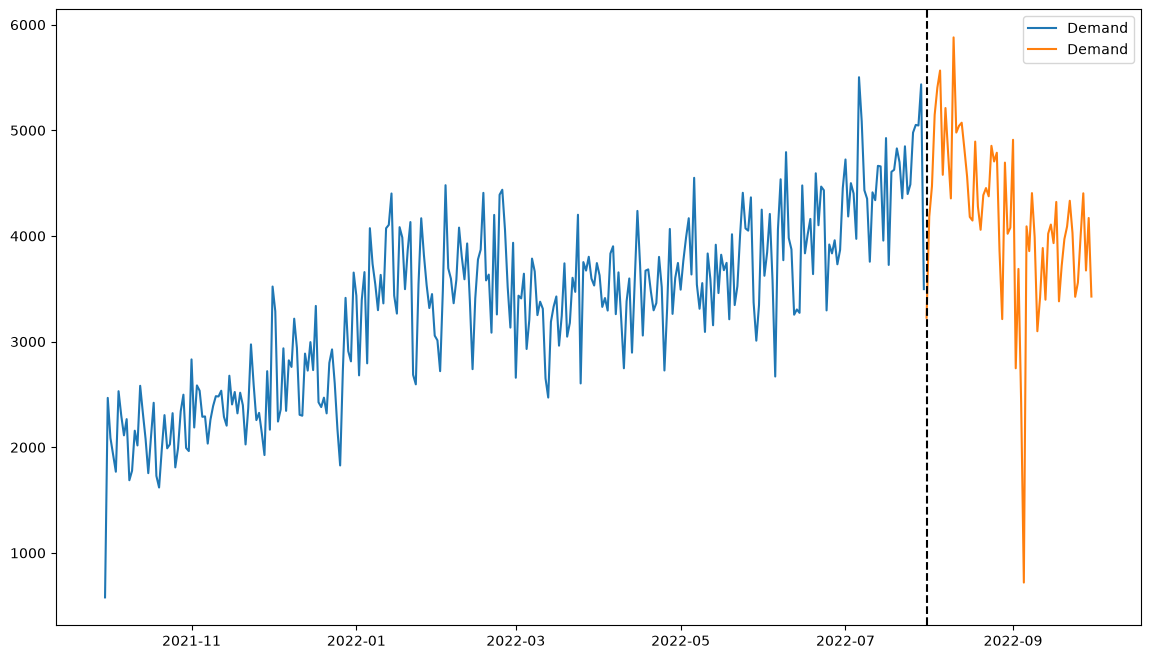

In [12]:
fig, ax = plt.subplots(figsize=(14,8))
train.plot(ax=ax,label='Train set')
test.plot(ax=ax,label='Test set')
plt.axvline('2022-07-31',color='black',ls='--')
plt.show()

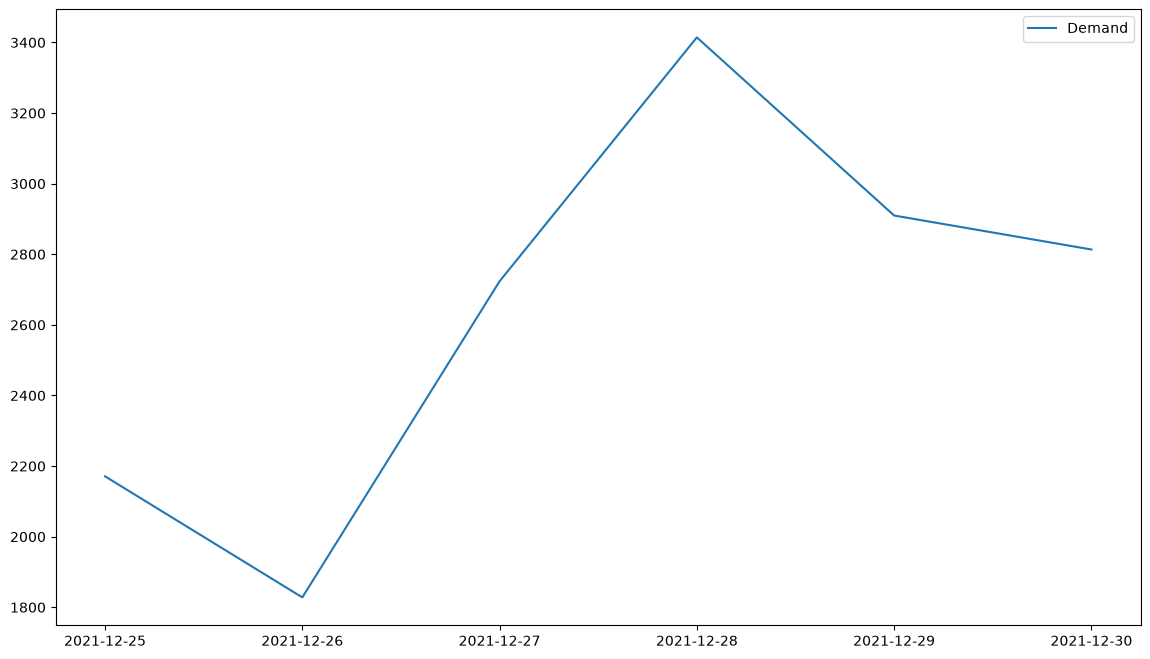

In [13]:
# visualize the weekly pattern
df_1.loc[(df_1.index > date(2021,12,24)) & (df_1.index < date(2021,12,31))].plot(
    figsize=(14,8)
)
plt.show()

#### Trend

<Axes: >

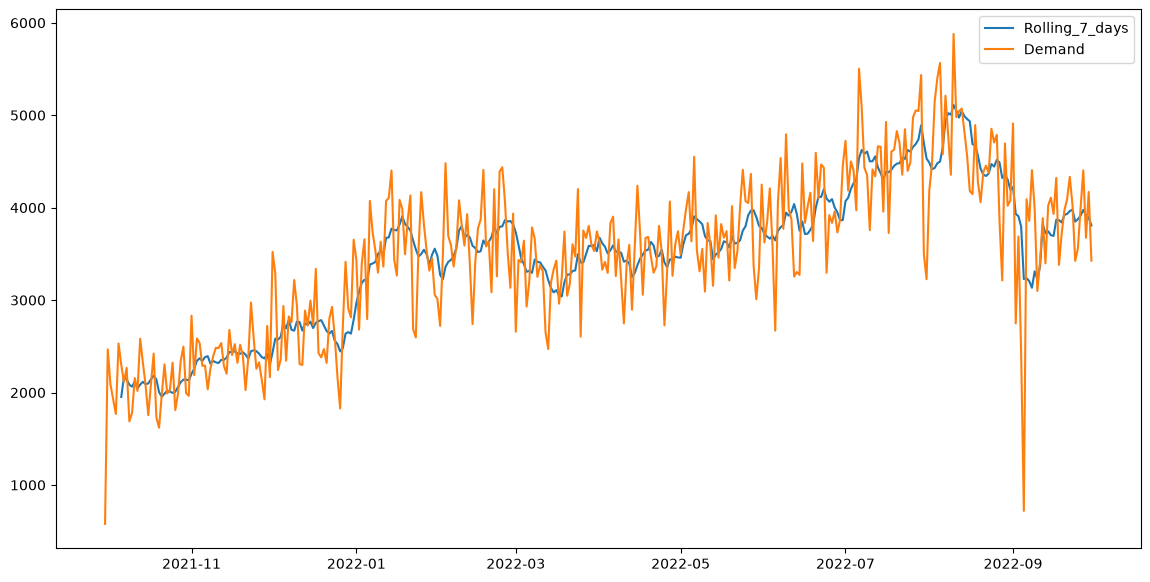

In [14]:
### 7 days rooling mean to see the actually trend in data, as daily demand has a lot of up and downs.

df_1['Rolling_7_days'] = df_1['Demand'].rolling(window=7).mean()

df_1[['Rolling_7_days','Demand']].plot(figsize=(14,7))

### Seasonality

In [15]:
df_1.index = pd.to_datetime(df_1.index)
df_1['Day_of_week'] = df_1.index.day_name()


In [16]:
df_1.sample(3)

,Demand,Rolling_7_days,Day_of_week
2021-10-31,1964.11,2131.211429,Sunday
2022-07-19,4626.81,4452.334286,Tuesday
2022-02-09,3805.90,3800.518571,Wednesday


In [17]:
df_1

,Demand,Rolling_7_days,Day_of_week
2021-09-30,579.19,NaN,Thursday
2021-10-01,2467.59,NaN,Friday
2021-10-02,2087.75,NaN,Saturday
2021-10-03,1928.25,NaN,Sunday
2021-10-04,1768.66,NaN,Monday
...,...,...,...
2022-09-26,3995.26,3914.534286,Monday
2022-09-27,4404.18,3976.531429,Tuesday
2022-09-28,3673.44,3917.011429,Wednesday
2022-09-29,4170.49,3893.730000,Thursday


In [18]:
df_week_days = df_1.groupby('Day_of_week')['Demand'].mean()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_week_days= df_week_days.reindex(days_order)

df_week_days

Day_of_week
Monday       3444.219808
Tuesday      3500.548462
Wednesday    3666.688077
Thursday     3674.215660
Friday       3594.285094
Saturday     3328.554808
Sunday       3076.941923
Name: Demand, dtype: float64

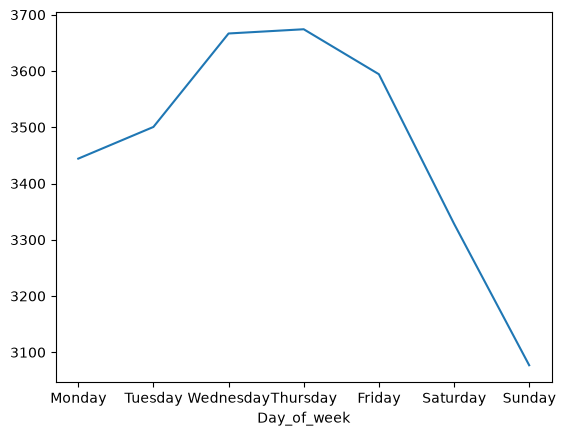

In [19]:
df_week_days.plot()
plt.show()

<Axes: xlabel='Day_of_week'>

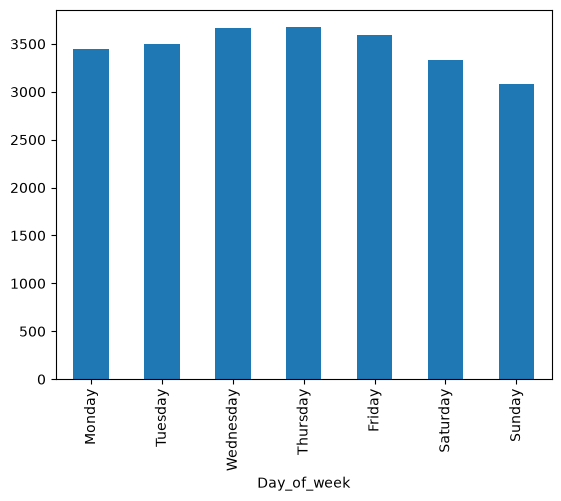

In [20]:
df_week_days.plot(kind='bar')

In [21]:
## Seasonality monthly basis

df_1['months'] = df_1.index.month_name()

In [22]:
df_1

,Demand,Rolling_7_days,Day_of_week,months
2021-09-30,579.19,NaN,Thursday,September
2021-10-01,2467.59,NaN,Friday,October
2021-10-02,2087.75,NaN,Saturday,October
2021-10-03,1928.25,NaN,Sunday,October
2021-10-04,1768.66,NaN,Monday,October
...,...,...,...,...
2022-09-26,3995.26,3914.534286,Monday,September
2022-09-27,4404.18,3976.531429,Tuesday,September
2022-09-28,3673.44,3917.011429,Wednesday,September
2022-09-29,4170.49,3893.730000,Thursday,September


In [23]:
## grouping month col nd taking avg of demand
df_month = df_1.groupby('months')['Demand'].mean()

In [24]:
df_month

months
April        3475.122333
August       4614.234516
December     2747.035161
February     3683.641429
January      3536.752581
July         4506.020968
June         3918.814000
March        3351.485484
May          3718.833226
November     2391.385000
October      2094.628387
September    3605.541935
Name: Demand, dtype: float64

In [25]:
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
df_month = df_month.reindex(month_order)

In [26]:
df_month

months
January      3536.752581
February     3683.641429
March        3351.485484
April        3475.122333
May          3718.833226
June         3918.814000
July         4506.020968
August       4614.234516
September    3605.541935
October      2094.628387
November     2391.385000
December     2747.035161
Name: Demand, dtype: float64

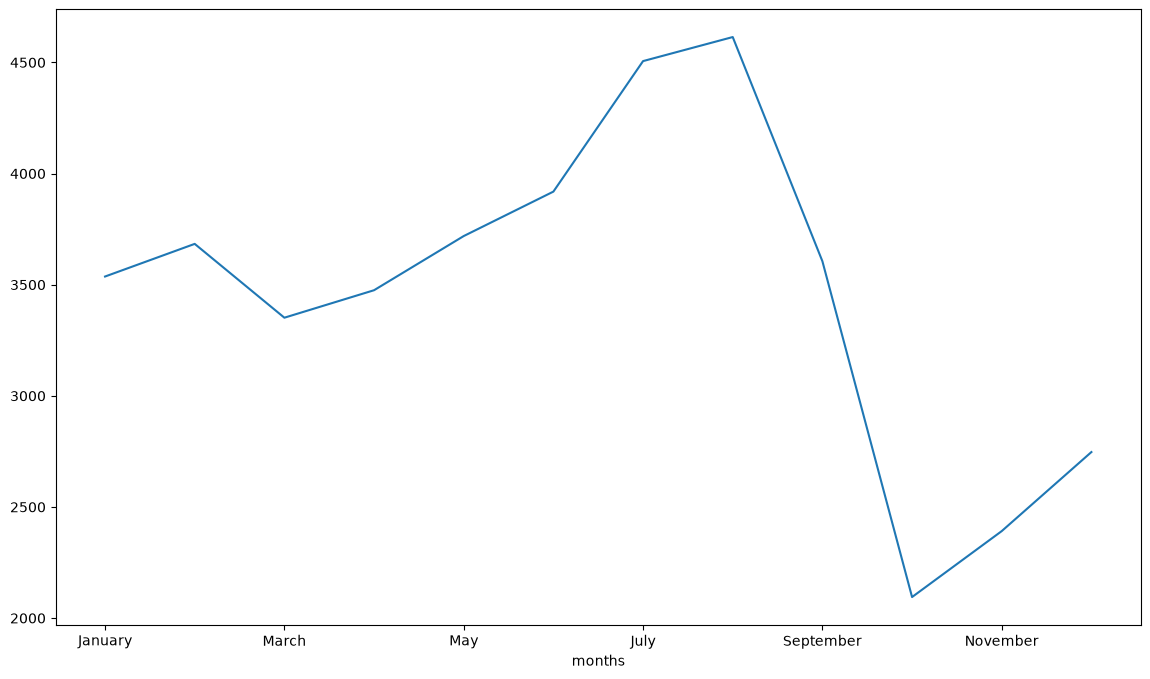

In [27]:
df_month.plot(figsize=(14,8))
plt.show()

<Axes: xlabel='months'>

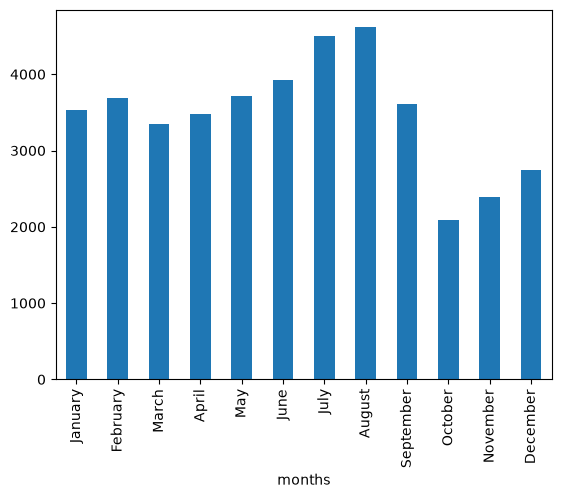

In [28]:
df_month.plot(kind='bar')

### Decompostion visualization

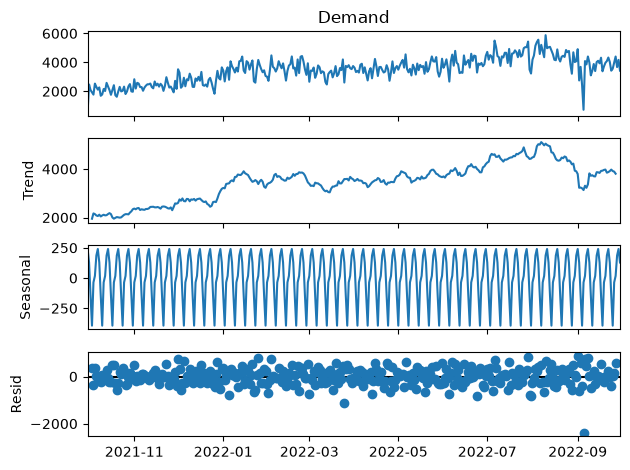

In [29]:
from statsmodels.tsa.seasonal import seasonal_decompose

decompostion = seasonal_decompose(
    df_1['Demand'],
    model='additive',
    period=7
)
decompostion.plot()
plt.show()

### Checking the whether the data is stationary or not

In [30]:
from statsmodels.tsa.stattools import adfuller

results = adfuller(df_1['Demand'],result_object=True)
results

ADFullerResult
ADF Statistic: -1.88081
P-value: 0.34114
Used Lag: 13
Nobs: 352
Critical Values: {'1%': np.float64(-3.4490648539347544), '5%': np.float64(-2.8697861692116478), '10%': np.float64(-2.5711631253228306)}

##### as our p-value is more than 0.05, so your data is non-stationary 

#### Moving Avg forecasting

In [31]:
window = 7
past_data = train['Demand'].to_list()

predication = []

for actual_value in test['Demand']:
    forecast = sum(past_data[-window:])/window
    predication.append(forecast)
    past_data.append(actual_value)
    

In [33]:
predication

[4699.121428571429,
 4531.745714285715,
 4488.182857142857,
 4415.84,
 4429.521428571429,
 4480.792857142857,
 4499.465714285715,
 4654.041428571429,
 4937.64,
 5022.397142857143,
 5005.7357142857145,
 5110.405714285714,
 5049.594285714286,
 4974.765714285714,
 5045.217142857143,
 4989.887142857143,
 4959.378571428571,
 4934.285714285715,
 4686.624285714285,
 4674.405714285715,
 4565.344285714285,
 4420.547142857143,
 4358.071428571428,
 4342.53,
 4370.477142857143,
 4471.504285714285,
 4444.604285714286,
 4517.338571428571,
 4488.707142857143,
 4321.094285714285,
 4355.518571428572,
 4304.854285714286,
 4194.181428571429,
 4223.511428571429,
 3932.054285714286,
 3907.777142857143,
 3795.0714285714284,
 3227.2114285714283,
 3237.247142857143,
 3205.5600000000004,
 3133.4557142857143,
 3310.8842857142854,
 3226.628571428572,
 3368.371428571428,
 3820.7342857142858,
 3721.552857142857,
 3745.117142857143,
 3702.6042857142857,
 3694.424285714286,
 3869.2542857142857,
 3864.2557142857145,


In [36]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

mae = mean_absolute_error(test,predication)
rmse = root_mean_squared_error(test,predication)
r2 = r2_score(test,predication)

print(mae)
print(rmse)
r2

514.5280875576037
714.2857315947693


0.19167209052075218

### Simple Expontional smoothing

In [37]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing


In [60]:
ses = SimpleExpSmoothing(train['Demand'],initialization_method='estimated')

ses = ses.fit()

predication = ses.forecast(len(test))

predication

/home/arson/.cache/pypoetry/virtualenvs/ev-project-8jc2ThtM-py3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


2022-07-31    4626.083913
2022-08-01    4626.083913
2022-08-02    4626.083913
2022-08-03    4626.083913
2022-08-04    4626.083913
                 ...     
2022-09-26    4626.083913
2022-09-27    4626.083913
2022-09-28    4626.083913
2022-09-29    4626.083913
2022-09-30    4626.083913
Freq: D, Length: 62, dtype: float64

In [62]:
mae = mean_absolute_error(test['Demand'],predication)
rmse = root_mean_squared_error(test['Demand'],predication)

r2 = r2_score(test['Demand'],predication)

print(mae)
print(rmse)
print(r2)

690.6380223130326
924.8734150515596
-0.35521505199615167
